# 人工知能 第5回 演習課題

## 学習モデルの改造

1. 以下の条件を満たすクラスを実装せよ
   - クラス名は`SimpleNet`
   - 初期化メソッドの引数として`input_size`, `idden_size`, `output_size`をとる
   - 入力層の大きさは`input_size`
   - 中間層は2つで大きさはどちらも`hidden_size`、活性化関数はReLU関数
   - 出力層の大きさは`output_size`、活性化関数はソフトマックス関数
   - 各層のパラメータの初期値は重みはランダム値に0.01を乗じたもの、バイアスは0
   - 損失関数は交差エントロピー誤差
  
2. 問1で実装した`SimpleNet`クラスを用いて以下の条件を満たすモデルを構築し、学習を行うプログラムを作成せよ
   - データセットはMNIST
   - バッチサイズは200でエポック数は20
   - 学習率は0.1
   - 入力層の大きさは784
   - 中間層は2つで大きさはどちらも100
   - 出力層の大きさは10

3. 問2で作成したモデルでMNISTデータセットの学習を行い、学習用データでの正答率とテスト用データでの正答率の推移をMatplotlibを用いてグラフ化せよ

4. 問1～3で実装したコードを**任意の生成AI**に渡し、どのような処理を行うコードか、どんな理論に基づいて実装されたコードであるか、より良い実装とするにはどこに手を加えればよいかを解説させよ。その後、以下内容を本問題の回答として記載せよ。
   - 利用した生成AIに関する情報
     - サービス名・モデル名・バージョン・URLなど
   - 生成AIに渡したプロンプト**全文**
   - 生成AIが出力した回答内容**全文**

### 演習課題のヒント

1. 講義内では以下のような条件のモデルで学習を行った
  - クラス名は「TwoLayerNet」
  - 初期化メソッドの引数として「input_size」「hidden_size」「output_size」「weight_rate=0.01」をとる
  - 入力層の大きさは「input_size」
  - 中間層は1つで大きさは「hidden_size」、活性化関数はシグモイド関数
  - 出力層の大きさは「output_size」、活性化関数はソフトマックス関数
  - 各層のパラメータの初期値は重みはランダム値に「weight_rate」を乗じたもの、バイアスは0
  - 損失関数は交差エントロピー誤差


2. 講義内では「TwoLayetNet」クラスを用いて以下の条件でモデルを構築し、学習を行った
  - データセットはMNIST
  - バッチサイズは100枚でエポック数は20
  - 学習率は0.1
  - 入力層の大きさは784
  - 中間層は1つで大きさは50
  - 出力層の大きさは10

**利用するモジュールのインポート**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%pip install scikit-learn
import sklearn
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


**データセットの読み込み・ミニバッチ作成メソッドの実装**

In [2]:
# MNISTデータセットの読み込み・前処理
def load_mnist():
    # MNISTデータセットのロード
    data_x, data_t = fetch_openml('mnist_784', version=1, data_home=".", return_X_y=True, as_frame=False)

    # データ整形
    mnist_x = data_x.astype(np.float32) / 255
    mnist_t = data_t.astype(np.int32)

    # 学習用データとテスト用データに分割
    train_x, test_x, train_t, test_t = train_test_split(mnist_x, mnist_t, test_size=10000)
    return (train_x, train_t), (test_x, test_t)

# ミニバッチの取得
def make_batch_index(data_size, batch_size):
    idx_list = np.arange(data_size)
    np.random.shuffle(idx_list)

    batch_list = []
    i = 0

    while i < (data_size / batch_size):
        start = i * batch_size
        end = (i+1) * batch_size

        batch_idx = idx_list[start:end]
        batch_list.append(batch_idx)

        i += 1

    return np.array(batch_list)

**活性化関数・損失関数の実装**

In [3]:
# ソフトマックス関数
def softmax(x):
    if x.ndim == 2:
        x = x - x.max(axis=1, keepdims=True)
        x = np.exp(x)
        x /= x.sum(axis=1, keepdims=True)
    elif x.ndim == 1:
        x = x - np.max(x)
        x = np.exp(x) / np.sum(np.exp(x))
    return x

# 交差エントロピー誤差
def cross_entropy_error(y, t):
    if y.ndim == 1:
        t = t.reshape(1, t.size)
        y = y.reshape(1, y.size)

    if t.size == y.size:
        t = t.argmax(axis=1)

    batch_size = y.shape[0]
    idx = np.arange(batch_size)
    return -np.sum(np.log(y[idx, t] + 1e-7)) / batch_size

**レイヤの実装**

In [4]:
class AffineLayer:
    def __init__(self, W, b):
        self.params = [W, b]
        self.grads = [np.zeros_like(W), np.zeros_like(b)]
        self.x = None

    def forward(self, x):
        W, b = self.params
        out = np.matmul(x, W) + b
        self.x = x
        return out

    def backward(self, dout):
        W, b = self.params
        dx = np.matmul(dout, W.T)
        dW = np.matmul(self.x.T, dout)
        db = np.sum(dout, axis=0)

        self.grads[0][...] = dW
        self.grads[1][...] = db
        return dx

class ReluLayer:
    def __init__(self):
        self.params, self.grads = [], []
        self.mask = None

    def forward(self, x):
        self.mask = (x <= 0)
        out = x.copy()
        out[self.mask] = 0
        return out

    def backward(self, dout):
        dout[self.mask] = 0
        dx = dout
        return dx

class SoftmaxWithLossLayer:
    def __init__(self):
        self.params, self.grads = [], []
        self.y = None
        self.t = None

    def forward(self, x, t):
        self.t = t
        self.y = softmax(x)
        if self.t.size == self.y.size:
            self.t = self.t.argmax(axis=1)
        loss = cross_entropy_error(self.y, self.t)
        return loss

    def backward(self, dout=1):
        batch_size = self.t.shape[0]
        dx = self.y.copy()
        dx[np.arange(batch_size), self.t] -= 1
        dx *= dout
        dx = dx / batch_size
        return dx

**回答欄**

In [5]:
# 問1 回答欄
class SimpleNet:
    def __init__(self, input_size, hidden_size, output_size, weight_rate=0.01):
        self.params = {}
        self.params['W1'] = weight_rate * np.random.randn(input_size, hidden_size)
        self.params['b1'] = np.zeros(hidden_size)
        self.params['W2'] = weight_rate * np.random.randn(hidden_size, hidden_size)
        self.params['b2'] = np.zeros(hidden_size)
        self.params['W3'] = weight_rate * np.random.randn(hidden_size, output_size)
        self.params['b3'] = np.zeros(output_size)

        # レイヤの生成（入力 -> Affine -> ReLU -> Affine -> ReLU -> Affine）
        self.layers = [
            AffineLayer(self.params['W1'], self.params['b1']),
            ReluLayer(),
            AffineLayer(self.params['W2'], self.params['b2']),
            ReluLayer(),
            AffineLayer(self.params['W3'], self.params['b3'])
        ]
        
        self.last_layer = SoftmaxWithLossLayer()

    def predict(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def loss(self, x, t):
        y = self.predict(x)
        return self.last_layer.forward(y, t)

    def accuracy(self, x, t):
        y = self.predict(x)
        y = np.argmax(y, axis=1)
        if t.ndim != 1:
            t = np.argmax(t, axis=1)
        accuracy = np.sum(y == t) / float(x.shape[0])
        return accuracy

    def gradient(self, x, t):

        self.loss(x, t)

        dout = 1
        dout = self.last_layer.backward(dout)
        layers = list(reversed(self.layers))
        for layer in layers:
            dout = layer.backward(dout)

        grads = {}
        grads['W1'] = self.layers[0].grads[0]
        grads['b1'] = self.layers[0].grads[1]
        grads['W2'] = self.layers[2].grads[0]
        grads['b2'] = self.layers[2].grads[1]
        grads['W3'] = self.layers[4].grads[0]
        grads['b3'] = self.layers[4].grads[1]
        
        return grads


/Users/unnosatsu/Library/Python/3.9/lib/python/site-packages/sklearn/datasets/_openml.py:75: RuntimeWarning: Invalid cache, redownloading file
  warn("Invalid cache, redownloading file", RuntimeWarning)
/Users/unnosatsu/Library/Python/3.9/lib/python/site-packages/sklearn/datasets/_openml.py:110: UserWarning: A network error occurred while downloading https://api.openml.org/data/v1/download/52667. Retrying...
  warn(


学習を開始します...
Epoch 1 | Train Acc: 0.2238 | Test Acc: 0.2169
Epoch 2 | Train Acc: 0.8147 | Test Acc: 0.8101
Epoch 3 | Train Acc: 0.8790 | Test Acc: 0.8749
Epoch 4 | Train Acc: 0.9095 | Test Acc: 0.9085
Epoch 5 | Train Acc: 0.9291 | Test Acc: 0.9289
Epoch 6 | Train Acc: 0.9419 | Test Acc: 0.9403
Epoch 7 | Train Acc: 0.9498 | Test Acc: 0.9463
Epoch 8 | Train Acc: 0.9566 | Test Acc: 0.9512
Epoch 9 | Train Acc: 0.9601 | Test Acc: 0.9551
Epoch 10 | Train Acc: 0.9653 | Test Acc: 0.9590
Epoch 11 | Train Acc: 0.9671 | Test Acc: 0.9603
Epoch 12 | Train Acc: 0.9714 | Test Acc: 0.9650
Epoch 13 | Train Acc: 0.9745 | Test Acc: 0.9670
Epoch 14 | Train Acc: 0.9758 | Test Acc: 0.9674
Epoch 15 | Train Acc: 0.9778 | Test Acc: 0.9676
Epoch 16 | Train Acc: 0.9794 | Test Acc: 0.9687
Epoch 17 | Train Acc: 0.9819 | Test Acc: 0.9708
Epoch 18 | Train Acc: 0.9796 | Test Acc: 0.9687
Epoch 19 | Train Acc: 0.9815 | Test Acc: 0.9684
Epoch 20 | Train Acc: 0.9834 | Test Acc: 0.9690


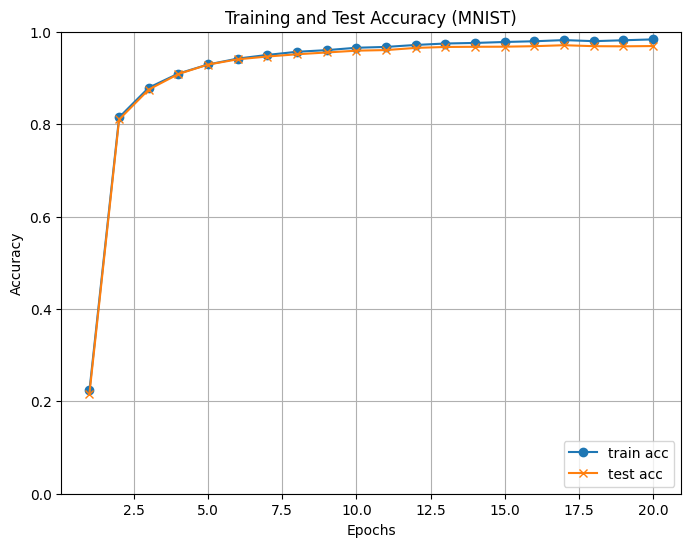

In [ ]:
# 問2 回答欄
(train_x, train_t), (test_x, test_t) = load_mnist()

train_size = train_x.shape[0]
batch_size = 200
epochs = 20
learning_rate = 0.1

network = SimpleNet(input_size=784, hidden_size=100, output_size=10)

iter_per_epoch = max(train_size / batch_size, 1)
epochs_list = []
train_acc_list = []
test_acc_list = []

print("学習を開始します...")
for i in range(epochs):
    batch_indices = make_batch_index(train_size, batch_size)
    
    for idx_list in batch_indices:
        x_batch = train_x[idx_list]
        t_batch = train_t[idx_list]
        
        grads = network.gradient(x_batch, t_batch)

        for key in ('W1', 'b1', 'W2', 'b2', 'W3', 'b3'):
            network.params[key] -= learning_rate * grads[key]
            
    train_acc = network.accuracy(train_x, train_t)
    test_acc = network.accuracy(test_x, test_t)
    
    train_acc_list.append(train_acc)
    test_acc_list.append(test_acc)
    epochs_list.append(i + 1)
    print(f"Epoch {i+1} | Train Acc: {train_acc:.4f} | Test Acc: {test_acc:.4f}")

plt.figure(figsize=(8, 6))
plt.plot(epochs_list, train_acc_list, marker='o', label='train acc')
plt.plot(epochs_list, test_acc_list, marker='x', label='test acc')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.ylim(0, 1.0)
plt.legend(loc='lower right')
plt.title("Training and Test Accuracy (MNIST)")
plt.grid(True)
plt.show()

# 問3 回答欄

サービス名：Google Gemini　1.5　Pro

渡したプロンプト：
「以下の人工知能の演習課題（SimpleNetを用いたMNISTの分類と学習コード）について、どのような処理を行うコードか、どんな理論（誤差逆伝播法やAffineレイヤ、ReLU、ソフトマックス・交差エントロピーなど）に基づいて実装されたコードであるか、より良い実装（過学習の抑制や最適化手法の変更など）にするにはどこに手を加えればよいかを解説してください。」

処理内容と理論:
本コードは、多層パーセプトロン（全結合層が2つの隠れ層を持つネットワーク）を用いて、手書き数字（MNIST）の多クラス分類を行うものです。順伝播（Forward Propagation）で予測値を算出し、出力層でソフトマックス関数と交差エントロピー誤差を用いて損失を計算します。その後、微分・チェーンルール（連鎖律）に基づく誤差逆伝播法（Backpropagation）により各パラメータ（重み・バイアス）の勾配を効率的に求め、確率的勾配降下法（SGD）でモデルを最適化しています。

より良い実装にするための改善案:

最適化手法の変更: 単純なSGDではなく、モメンタムやAdamなどの適応的学習率を持つオプティマイザを導入することで、収束速度や精度を向上させることができます。

正則化（過学習対策）: ドロップアウト（Dropout）や重み減衰（L2正則化）を導入することで、テストデータに対する汎用性能を高めることができます。